In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carga de datos

Comenzamos por descargar el dataset y ver la información que contiene

In [76]:
df = pd.read_csv("../ProyectoFinal_ML/rendimiento_estudiantes.csv", sep=";")

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   estado_civil                       4424 non-null   object 
 1   modo_solicitud                     4424 non-null   object 
 2   orden_solicitud                    4424 non-null   int64  
 3   curso                              4424 non-null   object 
 4   asistencia_diurna_vespertina       4424 non-null   object 
 5   cualificacion_previa               4424 non-null   object 
 6   nota_cualificacion_previa          4424 non-null   float64
 7   nacionalidad                       4424 non-null   object 
 8   cualificacion_madre                4424 non-null   object 
 9   cualificacion_padre                4424 non-null   object 
 10  ocupacion_madre                    4424 non-null   object 
 11  ocupacion_padre                    4424 non-null   objec

In [78]:
var_num = df.select_dtypes(include=["number"]).columns.tolist()
var_cat = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Número de variables numéricas: {len(var_num)}\nNúmero variables categóricas: {len(var_cat)}")

Número de variables numéricas: 19
Número variables categóricas: 18


Se observa las distintas variables categóricas, que valores pueden tomar

In [79]:
columns = list(df.columns)
for col in columns:
    indx, series = pd.factorize(df[col])
    print(f"Columna: {col}\nValores {len(series)}:\n{series}\n")

Columna: estado_civil
Valores 6:
Index(['soltero/a', 'casado/a', 'divorciado/a', 'viudo/a', 'union_de_hecho',
       'separado/a_legalmente'],
      dtype='object')

Columna: modo_solicitud
Valores 18:
Index(['2a_fase_contingente_general', 'estudiante_internacional_licenciatura',
       '1a_fase_contingente_general', 'mayor_de_23_anos',
       '3a_fase_contingente_general', 'titular_de_diploma_de_ciclo_corto',
       'titular_de_diploma_de_especializacion_tecnologica',
       'cambio_de_institucion_curso', 'cambio_de_curso',
       'titular_de_otro_curso_superior', 'traslado',
       '1a_fase_contingente_especial_madeira',
       '1a_fase_contingente_especial_azores', 'ordenanza_612_93',
       'ordenanza_854_b_99', 'cambio_de_institucion_curso_internacional',
       'ordenanza_533_a_99_apartado_b2_plan_diferente',
       'ordenanza_533_a_99_apartado_b3_otra_institucion'],
      dtype='object')

Columna: orden_solicitud
Valores 8:
Index([5, 1, 2, 4, 3, 6, 9, 0], dtype='int64')

Columna

## 2. Variables numéricas

Una vez observado y leído el dataset he observado que hay casos en los que el número de asignaturas evaluadas es superior al de matriculadas lo cual es imposible, por lo tanto, corregimos el error.

EVALUADAS Y MATRICULADAS

In [80]:
(df["asignaturas_1sem_evaluadas"]>df["asignaturas_1sem_matriculadas"]).value_counts()

True     2792
False    1632
Name: count, dtype: int64

Dado que algo menos de la mitad del dataset sí que ha sido evaluado en más asignaturas que en las que se ha matriculado deducimos que no es un fallo en la recogida de datos.

    Correlación entre las variables numéricas

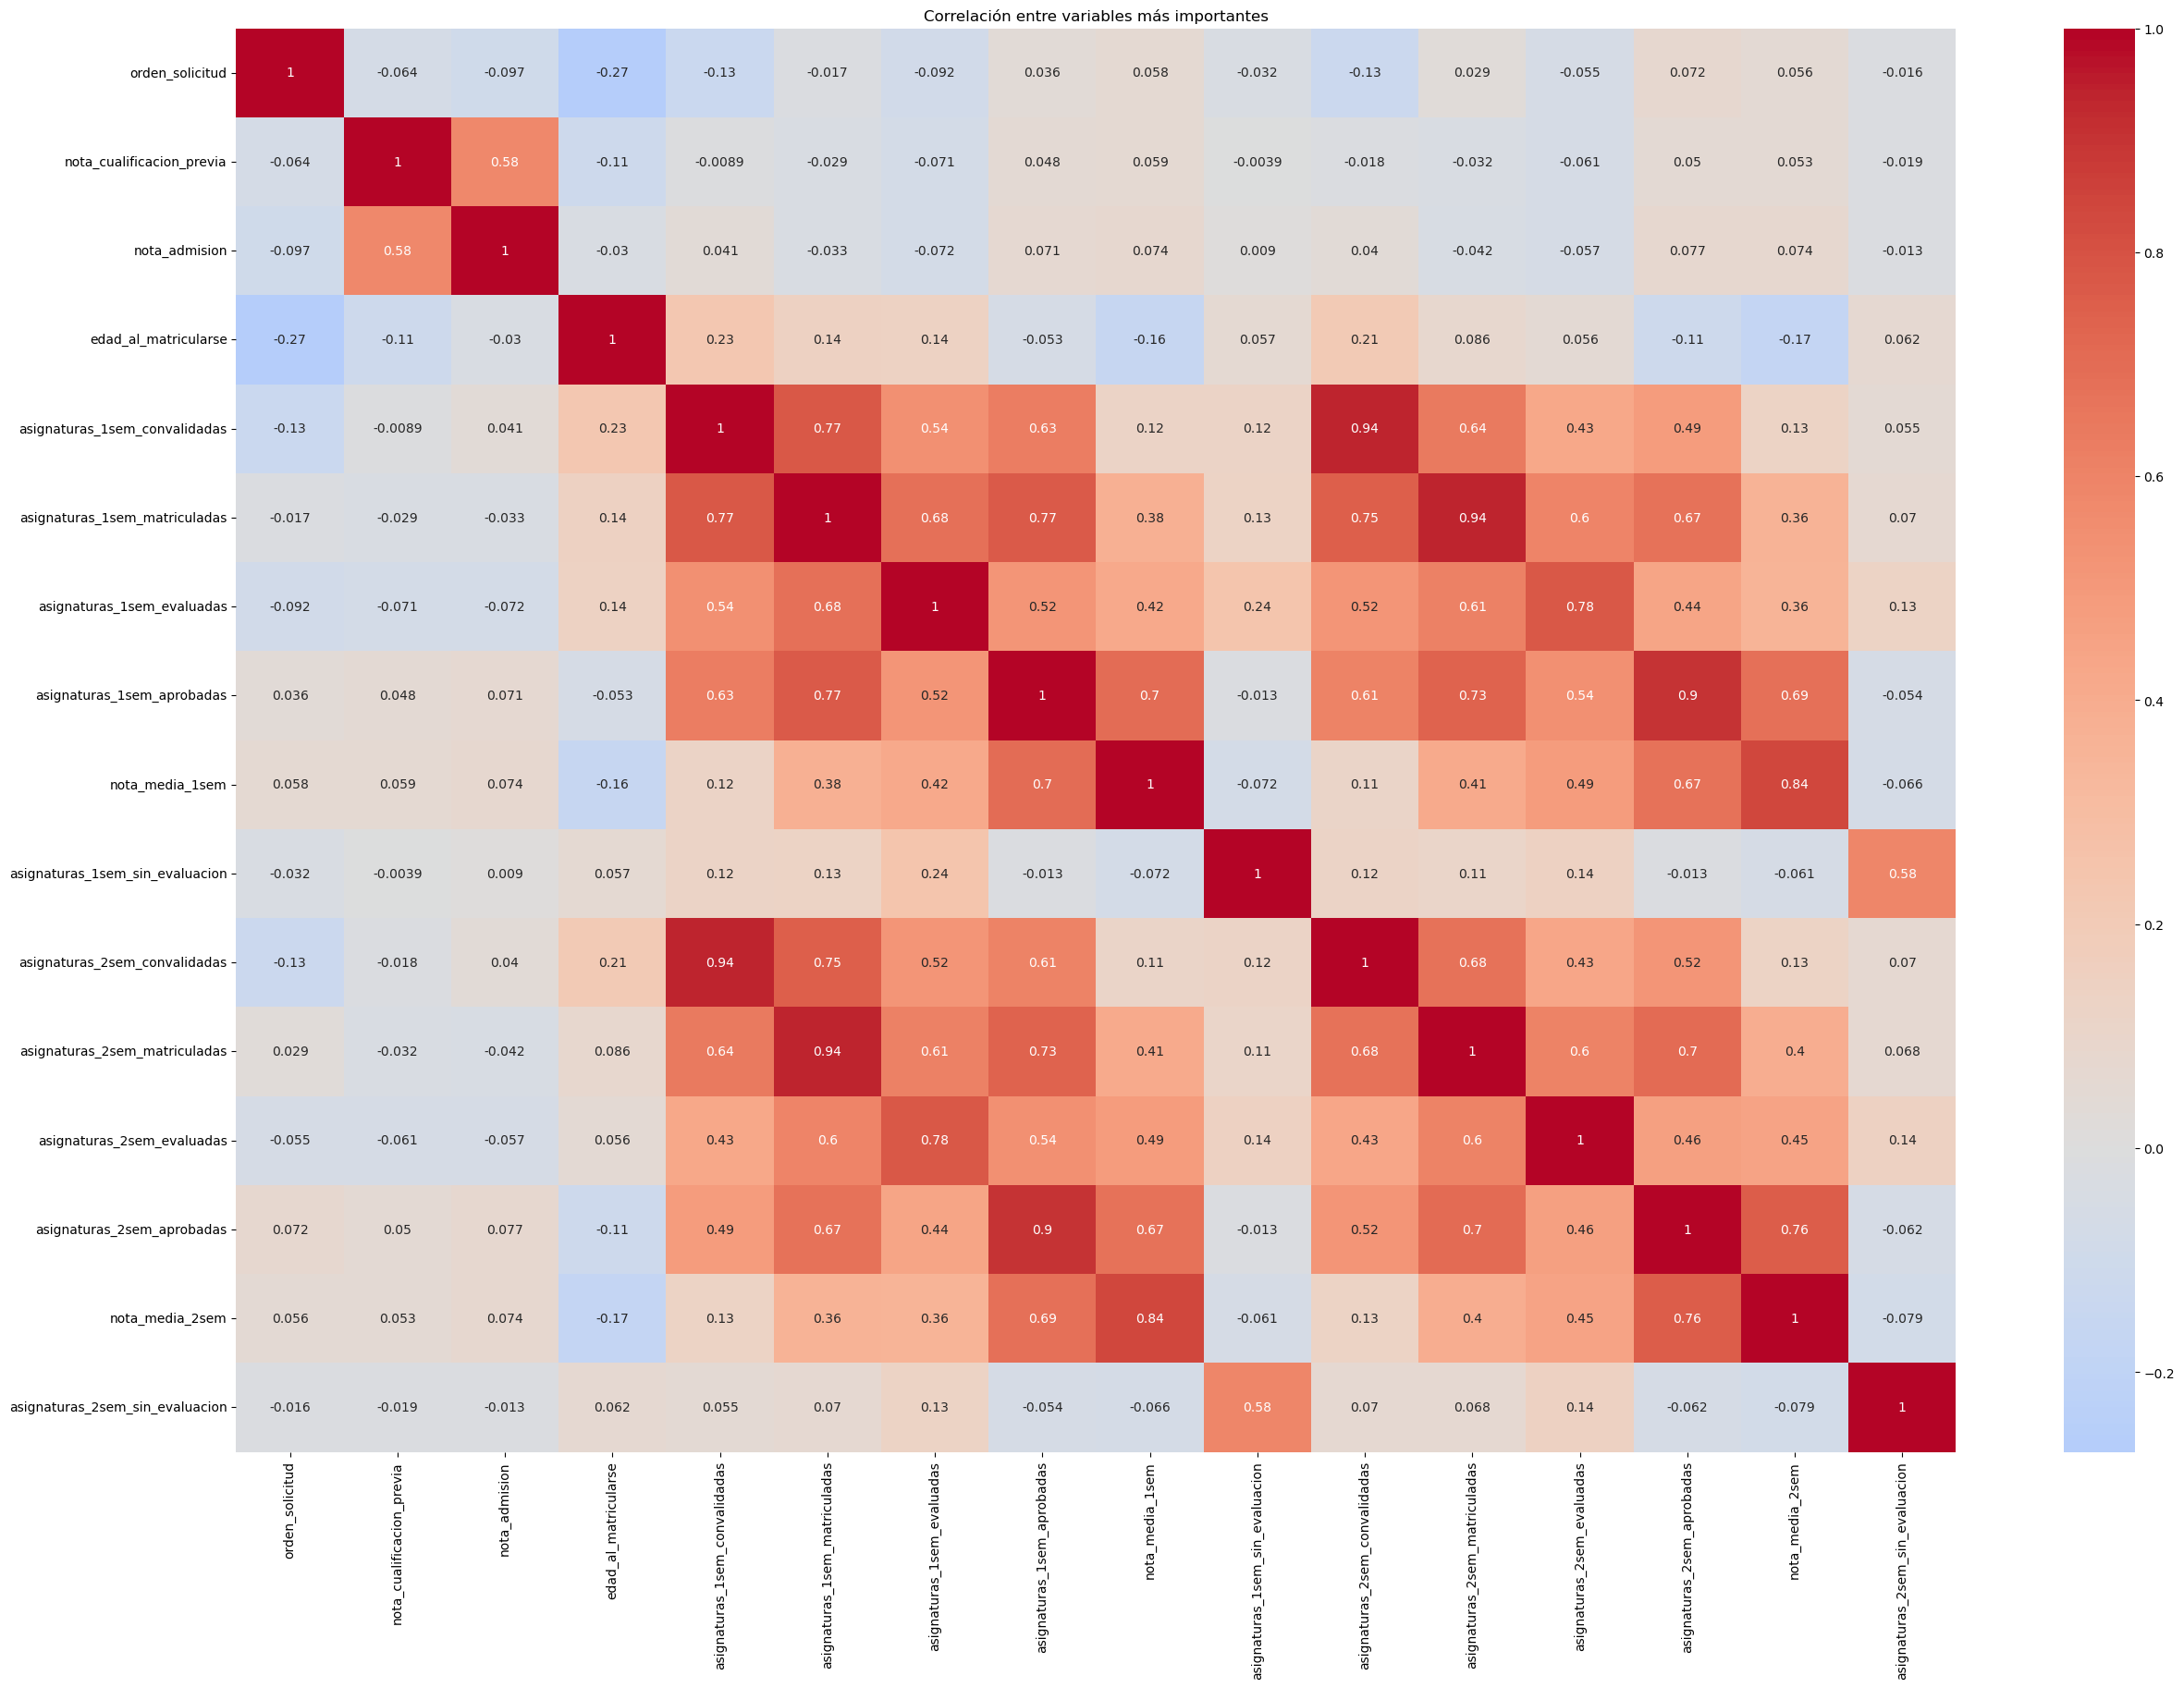

In [81]:
var_no = ["tasa_desempleo", "tasa_inflacion", "pib"]

plt.figure(figsize=(30,20))
sns.heatmap(df.drop(columns=var_no, axis=1).corr(numeric_only=True), annot=True, cmap="coolwarm", center=0)
plt.title("Correlación entre variables más importantes")
plt.show()

Una vez he realizado la comparación, he observado que esta relación no se da en aproximadamente el 10% de los datos. Esto nos da a entender que estas variables no presentan una relación estricta, sino que son medidas distintas que tienen definiciones solapadas, por ello he decidido no realizar ningún cambio.

## 3. Variables categóricas

In [82]:
for var in var_cat:
    indx, series = pd.factorize(df[var])
    print(f"Columna: {var}\nValores: {len(series)}\n")

Columna: estado_civil
Valores: 6

Columna: modo_solicitud
Valores: 18

Columna: curso
Valores: 17

Columna: asistencia_diurna_vespertina
Valores: 2

Columna: cualificacion_previa
Valores: 17

Columna: nacionalidad
Valores: 21

Columna: cualificacion_madre
Valores: 29

Columna: cualificacion_padre
Valores: 34

Columna: ocupacion_madre
Valores: 32

Columna: ocupacion_padre
Valores: 46

Columna: desplazado
Valores: 2

Columna: necesidades_educativas_especiales
Valores: 2

Columna: deudor
Valores: 2

Columna: matricula_al_dia
Valores: 2

Columna: genero
Valores: 2

Columna: becado
Valores: 2

Columna: internacional
Valores: 2

Columna: objetivo
Valores: 3



ESTADO CIVIL

In [83]:
df["estado_civil"].value_counts()

estado_civil
soltero/a                3919
casado/a                  379
divorciado/a               91
union_de_hecho             25
separado/a_legalmente       6
viudo/a                     4
Name: count, dtype: int64

Dado que la variable de estado civil esta fuertemente desbalanceada con claramente con algunas de sus categorías poco representadas, he decidido agruparla en una versión binaria: con_pareja y sin_pareja

In [84]:
df["estado_civil"] = df["estado_civil"].replace({"casado/a": "con_pareja",
                                                "soltero/a": "sin_pareja",
                                                "divorciado/a": "sin_pareja",
                                                "union_de_hecho": "con_pareja",
                                                "separado/a_legalmente": "sin_pareja",
                                                "viudo/a": "sin_pareja"})

In [85]:
df["estado_civil"].value_counts()

estado_civil
sin_pareja    4020
con_pareja     404
Name: count, dtype: int64

MODO_SOLICITUD

In [86]:
df["modo_solicitud"].value_counts()

modo_solicitud
1a_fase_contingente_general                          1708
2a_fase_contingente_general                           872
mayor_de_23_anos                                      785
cambio_de_curso                                       312
titular_de_diploma_de_especializacion_tecnologica     213
titular_de_otro_curso_superior                        139
3a_fase_contingente_general                           124
traslado                                               77
cambio_de_institucion_curso                            59
1a_fase_contingente_especial_madeira                   38
titular_de_diploma_de_ciclo_corto                      35
estudiante_internacional_licenciatura                  30
1a_fase_contingente_especial_azores                    16
ordenanza_854_b_99                                     10
ordenanza_612_93                                        3
cambio_de_institucion_curso_internacional               1
ordenanza_533_a_99_apartado_b2_plan_diferente           1

Para esta segunda variable, podemos una vez más observar que las clases están notablemente desbalanceadas, por lo que he decidido reagruparlas de una manera que tenga un mayor sentido en vez de hacerlo por frecuencias porque de esta segunda información podría perder información importante, como aquellos que son mayores de una edad etc. De esta manera se va a intentar que el dataset sea más interpretable a la hora de hacer los apartados pertinentes posteriores.

In [87]:
df["modo_solicitud"].replace({"cambio_de_curso": "cambios_internos",
                                                "traslado": "cambios_internos",
                                                "cambio_de_institucion_curso": "cambios_internos",
                                                "titular_de_otro_curso_superior": "titulados",
                                                "titular_de_diploma_de_especializacion_tecnologica": "titulados",
                                                "titular_de_diploma_de_ciclo_corto": "titulados",
                                                "estudiante_internacional_licenciatura": "internacional",
                                                "cambio_de_institucion_curso_internacional":"internacional",
                                                "ordenanza_854_b_99":"casos_administrativos",
                                                "ordenanza_854_b_99":"casos_administrativos",
                                                "ordenanza_533_a_99_apartado_b2_plan_diferente": "casos_administrativos",
                                                "ordenanza_533_a_99_apartado_b3_otra_institucion":"casos_administrativos",
                                                "ordenanza_612_93": "casos_administrativos"}, inplace=True)
df["modo_solicitud"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\538009336.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["modo_solicitud"].replace({"cambio_de_curso": "cambios_internos",


modo_solicitud
1a_fase_contingente_general             1708
2a_fase_contingente_general              872
mayor_de_23_anos                         785
cambios_internos                         448
titulados                                387
3a_fase_contingente_general              124
1a_fase_contingente_especial_madeira      38
internacional                             31
1a_fase_contingente_especial_azores       16
casos_administrativos                     15
Name: count, dtype: int64

CUALIFICACIÓN PREVIA

In [88]:
df["cualificacion_previa"].value_counts()

cualificacion_previa
educacion_secundaria                        3717
curso_de_especializacion_tecnologica         219
educacion_basica_3er_ciclo_o_equivalente     162
educacion_superior_grado                     126
otro_11o_ano                                  45
educacion_superior_grado_1er_ciclo            40
curso_tecnico_superior_profesional            36
educacion_superior_licenciatura               23
asistencia_previa_a_educacion_superior        16
12o_ano_no_completado                         11
educacion_superior_master                      8
educacion_basica_2o_ciclo_o_equivalente        7
educacion_superior_master_2o_ciclo             6
11o_ano_no_completado                          4
10o_ano_no_completado                          2
educacion_superior_doctorado                   1
10o_ano                                        1
Name: count, dtype: int64

Una vez más, llevaremos a cabo una agrupación de variables para que las categorías dentro de la clase no estén tan desbalanceadas. Esta nueva agrupación la realizaremos por ciclos completados: educacion_secundaria, grado_superior, educacion_superior_grado, educacion_superior_master...

In [89]:
df["cualificacion_previa"].replace({"otro_11o_ano":"educacion_secundaria",
                                    "educacion_basica_2o_ciclo_o_equivalente":"educacion_secundaria",
                                    "educacion_basica_3er_ciclo_o_equivalente":"educacion_secundaria",
                                    "10o_ano":"educacion_secundaria",
                                    "12o_ano_no_completado":"secundaria_no_completado",
                                    "11o_ano_no_completado": "secundaria_no_completado",
                                    "10o_ano_no_completado":"secundaria_no_completado",
                                    "curso_de_especializacion_tecnologica":"grado_superior",
                                    "curso_tecnico_superior_profesional":"grado_superior",
                                    "asistencia_previa_a_educacion_superior": "grado_superior",
                                    "educacion_superior_licenciatura":"educacion_superior_grado",
                                    "educacion_superior_grado_1er_ciclo":"educacion_superior_grado",
                                    "educacion_superior_master_2o_ciclo":"educacion_superior_master"}, inplace=True)
df["cualificacion_previa"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\2899754023.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["cualificacion_previa"].replace({"otro_11o_ano":"educacion_secundaria",


cualificacion_previa
educacion_secundaria            3932
grado_superior                   271
educacion_superior_grado         189
secundaria_no_completado          17
educacion_superior_master         14
educacion_superior_doctorado       1
Name: count, dtype: int64

NACIONALIDAD

In [90]:
print(f"Nacionalidades:\n{df["nacionalidad"].value_counts()}\n")
print(f"Internacionalidad:\n{df["internacional"].value_counts()}")

Nacionalidades:
nacionalidad
portuguesa      4314
brasilena         38
santotomense      14
caboverdiana      13
espanola          13
guineana           5
moldava            3
italiana           3
ucraniana          3
angolana           2
mexicana           2
rumana             2
mozambiquena       2
alemana            2
rusa               2
turca              1
neerlandesa        1
colombiana         1
cubana             1
inglesa            1
lituana            1
Name: count, dtype: int64

Internacionalidad:
internacional
no    4314
si     110
Name: count, dtype: int64


Como se puede observar en el código anterior, la variable nacionalidades presenta un fuerte desbalanceo con una clara dominancia de la variable portuguesa y el resto de categorías con menos frecuencia. Por otro lado, observando la variable internacional podemos observar que el valor de nacional coincide con el de portuguesa en la variable nacionalidad por lo que se puede deducir que la información de esta última columna puede ser sintetizada por la de la columna de internacional. Llegadas a estas conclusiones se ha decidido eliminar la variable nacionalidad, reduciendo dimensionalidad y evitando la introducción de ruido al modelo.

In [91]:
df.drop(columns=["nacionalidad"], inplace=True)

NO CONOCIDOS

OCUPACIÓN Y CUALIFICACIÓN DE LOS PROGENITORES

In [92]:
print((df["ocupacion_madre"]=="en_blanco").sum())
print((df["ocupacion_padre"]=="en_blanco").sum())
print((df["cualificacion_madre"]=="desconocido").sum())
print((df["cualificacion_padre"]=="desconocido").sum())
print(df.shape)
print((17+19+130+112)/4424)


17
19
130
112
(4424, 36)
0.0628390596745027


Como se puede observar en el cálculo anterior, dado que los datos en las que la información de los progenitores es desconocida llega aproximadamente a un 6% del dataset he decidido no eliminarlo, sino mantenerlo como desconocido.

In [93]:
# Para empezar, sustituimos la variable de en_blanco por la variable desconocido para que sea todo más homogéneo
df["ocupacion_madre"] = df["ocupacion_madre"].replace("en_blanco", "desconocido")
df["ocupacion_padre"] = df["ocupacion_padre"].replace("en_blanco", "desconocido")


A continuación, de la misma manera que lo que hemos hecho en variables anteriores como eran los grados de educación, voy a categorizar tanto la educación como ocupación de los progenitores.   
**Educación:** la variable de educación de los progenitores la voy a categorizar de manera similar a la de los alumnos, pues una vez más, dependiendo de la educación que ha recibido tiene unos conocimientos/capacidades distintas teniendo probablemente un efecto en la educación del alumno.   
**Ocupación:** esta segunda variable, voy a calificar sus características dependiendo de las cualificaciones que tengan que tener para realizar dichas tareas.  

**EDUCACION MADRE**

In [94]:
df["cualificacion_madre"].value_counts()

cualificacion_madre
educacion_secundaria_12o_ano_o_equivalente    1069
educacion_basica_1er_ciclo_o_equivalente      1009
educacion_basica_3er_ciclo_o_equivalente       953
educacion_basica_2o_ciclo_o_equivalente        562
educacion_superior_grado                       438
desconocido                                    130
educacion_superior_licenciatura                 83
educacion_superior_master                       49
otro_11o_ano                                    42
educacion_superior_doctorado                    21
educacion_superior_grado_1er_ciclo               9
12o_ano_no_completado                            8
curso_de_especializacion_tecnologica             8
curso_superior_especializado                     6
frecuencia_de_educacion_superior                 4
curso_tecnico_superior_profesional               4
educacion_superior_master_2o_ciclo               4
9o_ano_no_completado                             3
11o_ano_no_completado                            3
7o_ano_anti

In [95]:
df["cualificacion_madre"].replace({"educacion_secundaria_12o_ano_o_equivalente": "educacion_secundaria",
                                    "educacion_basica_1er_ciclo_o_equivalente": "educacion_basica",
                                    "educacion_basica_3er_ciclo_o_equivalente": "educacion_secundaria",
                                    "educacion_basica_2o_ciclo_o_equivalente": "educacion_secundaria",
                                    "educacion_superior_grado": "educacion_superior_grado",
                                    "desconocido": "desconocido",
                                    "educacion_superior_licenciatura": "educacion_superior_grado",
                                    "educacion_superior_master": "educacion_superior_master",
                                    "otro_11o_ano": "educacion_secundaria",
                                    "educacion_superior_doctorado": "educacion_superior_doctorado",
                                    "educacion_superior_grado_1er_ciclo": "educacion_superior_grado",
                                    "12o_ano_no_completado": "secundaria_no_completado",
                                    "curso_de_especializacion_tecnologica": "grado_superior",
                                    "curso_superior_especializado": "grado_superior",
                                    "frecuencia_de_educacion_superior": "grado_superior",
                                    "curso_tecnico_superior_profesional": "grado_superior",
                                    "educacion_superior_master_2o_ciclo": "educacion_superior_master",
                                    "9o_ano_no_completado": "educacion_basica_no_completado",
                                    "11o_ano_no_completado": "secundaria_no_completado",
                                    "7o_ano_antiguo": "educacion_basica",
                                    "sabe_leer_sin_4o_ano": "educacion_basica_no_completado",
                                    "no_sabe_leer_ni_escribir": "educacion_basica_no_completado",
                                    "8o_ano": "educacion_basica",
                                    "10o_ano": "educacion_secundaria",
                                    "curso_general_de_comercio": "grado_medio",
                                    "curso_tecnico_profesional": "grado_medio",
                                    "2o_ciclo_del_bachillerato_general": "educacion_secundaria",
                                    "7o_ano": "educacion_basica",
                                    "educacion_superior_doctorado_3er_ciclo": "educacion_superior_doctorado"}, inplace=True)
df["cualificacion_madre"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\3806430247.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["cualificacion_madre"].replace({"educacion_secundaria_12o_ano_o_equivalente": "educacion_secundaria",


cualificacion_madre
educacion_secundaria              2629
educacion_basica                  1016
educacion_superior_grado           530
desconocido                        130
educacion_superior_master           53
grado_superior                      22
educacion_superior_doctorado        22
secundaria_no_completado            11
educacion_basica_no_completado       9
grado_medio                          2
Name: count, dtype: int64

**OCUPACIÓN MADRE:**  
`Trabajos con cualificaciones bajas:`     
            - trabajadoras_no_cualificadas  
            - personal_de_limpieza  
            - ayudantes_de_preparacion_de_comidas   
            - trabajadoras_no_cualificadas_de_agricultura_ganaderia_pesca_y_silvicultura    
            - trabajadoras_no_cualificadas_de_industria_extractiva_construccion_manufactura_y_transporte    
        `Trabajos con cualificaciones medias:`     
            - trabajadoras_de_servicios_personales_seguridad_y_vendedoras    
            - vendedoras     
            - cuidadoras_y_trabajadoras_de_atencion_personal 
            - trabajadoras_de_servicios_personales   
            - operadoras_de_instalaciones_y_maquinaria_y_montadoras  
            - agricultoras_y_trabajadoras_cualificadas_de_agricultura_pesca_y_silvicultura   
            - trabajadoras_cualificadas_de_industria_construccion_y_artesania 
            - trabajadoras_de_industrias_alimentarias_madera_confeccion_y_otras_industrias_y_artes  
            - trabajadoras_cualificadas_de_la_construccion_excepto_electricistas  
            - trabajadoras_cualificadas_de_impresion_instrumentos_de_precision_joyeria_y_artesania     
        `Trabajos con cualificaciones intermedias:`     
            - tecnicos_y_profesiones_de_nivel_intermedio 
            - personal_administrativo   
            - empleadas_de_oficina_secretarias_y_operadoras_de_procesamiento_de_datos    
            - docentes  
            - otro_personal_de_apoyo_administrativo    
            - tecnicas_intermedias_de_servicios_juridicos_sociales_deportivos_culturales_y_similares    
            - profesiones_de_las_fuerzas_armadas   
            - operadoras_de_datos_contabilidad_estadistica_servicios_financieros_y_registro 
            - tecnicas_y_profesionales_intermedias_de_salud 
            - tecnicas_y_profesiones_intermedias_de_ciencia_e_ingenieria    
        `Trabajos con cualificaciones altas:`     
            - especialistas_en_actividades_intelectuales_y_cientificas  
            - especialistas_en_tic  
            - representantes_del_poder_legislativo_y_ejecutivo_directores_y_gerentes_ejecutivos 
            - profesionales_de_la_salud             
        `Otros casos/ casos particulares:`  
            - estudiante    
            - otra_situacion    
            - desconocido

In [96]:
df["ocupacion_madre"].value_counts()

ocupacion_madre
trabajadoras_no_cualificadas                                                                  1577
personal_administrativo                                                                        817
trabajadoras_de_servicios_personales_seguridad_y_vendedoras                                    530
tecnicos_y_profesiones_de_nivel_intermedio                                                     351
especialistas_en_actividades_intelectuales_y_cientificas                                       318
trabajadoras_cualificadas_de_industria_construccion_y_artesania                                272
estudiante                                                                                     144
representantes_del_poder_legislativo_y_ejecutivo_directores_y_gerentes_ejecutivos              102
agricultoras_y_trabajadoras_cualificadas_de_agricultura_pesca_y_silvicultura                    91
otra_situacion                                                                               

In [97]:
df["ocupacion_madre"].replace({ # Cualificación baja
                                "trabajadoras_no_cualificadas_de_agricultura_ganaderia_pesca_y_silvicultura":"trabajo_cualificaciones_bajas",
                               "trabajadoras_no_cualificadas_de_industria_extractiva_construccion_manufactura_y_transporte":"trabajo_cualificaciones_bajas",
                               "trabajadoras_no_cualificadas":"trabajo_cualificaciones_bajas",
                               "personal_de_limpieza": "trabajo_cualificaciones_bajas",
                               "ayudantes_de_preparacion_de_comidas": "trabajo_cualificaciones_bajas",
                               
                               # Cualificación media
                               "vendedoras": "trabajo_cualificacion_media",
                                "trabajadoras_de_servicios_personales_seguridad_y_vendedoras":"trabajo_cualificacion_media",
                                "cuidadoras_y_trabajadoras_de_atencion_personal":"trabajo_cualificacion_media",
                                "trabajadoras_de_servicios_personales":"trabajo_cualificacion_media",
                                "operadoras_de_instalaciones_y_maquinaria_y_montadoras":"trabajo_cualificacion_media",
                                "agricultoras_y_trabajadoras_cualificadas_de_agricultura_pesca_y_silvicultura":"trabajo_cualificacion_media",
                                "trabajadoras_cualificadas_de_industria_construccion_y_artesania":"trabajo_cualificacion_media",
                                "trabajadoras_de_industrias_alimentarias_madera_confeccion_y_otras_industrias_y_artes":"trabajo_cualificacion_media",
                                "trabajadoras_cualificadas_de_la_construccion_excepto_electricistas":"trabajo_cualificacion_media",
                                "trabajadoras_cualificadas_de_impresion_instrumentos_de_precision_joyeria_y_artesania":"trabajo_cualificacion_media",
                                
                                # Cualificación intermedia
                                "tecnicos_y_profesiones_de_nivel_intermedio":"trabajo_cualificacion_intermedia",
                                "personal_administrativo":"trabajo_cualificacion_intermedia",
                                "empleadas_de_oficina_secretarias_y_operadoras_de_procesamiento_de_datos":"trabajo_cualificacion_intermedia",
                                "docentes":"trabajo_cualificacion_intermedia",
                                "otro_personal_de_apoyo_administrativo":"trabajo_cualificacion_intermedia",
                                "tecnicas_intermedias_de_servicios_juridicos_sociales_deportivos_culturales_y_similares":"trabajo_cualificacion_intermedia",
                                "profesiones_de_las_fuerzas_armadas":"trabajo_cualificacion_intermedia",
                                "operadoras_de_datos_contabilidad_estadistica_servicios_financieros_y_registro":"trabajo_cualificacion_intermedia",
                                "tecnicas_y_profesionales_intermedias_de_salud":"trabajo_cualificacion_intermedia",
                                "tecnicas_y_profesiones_intermedias_de_ciencia_e_ingenieria":"trabajo_cualificacion_intermedia",
                                
                                # Cualificación alta       
                                "especialistas_en_actividades_intelectuales_y_cientificas":"trabajo_cualificacion_alta",
                                "especialistas_en_tic":"trabajo_cualificacion_alta",
                                "representantes_del_poder_legislativo_y_ejecutivo_directores_y_gerentes_ejecutivos":"trabajo_cualificacion_alta",
                                "profesionales_de_la_salud":"trabajo_cualificacion_alta",
                                
                                # Casos particulares
                                "estudiante":"otra_situacion",
                                "desconocido":"otra_situacion"}, inplace=True)
df["ocupacion_madre"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\573585486.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["ocupacion_madre"].replace({ # Cualificación baja


ocupacion_madre
trabajo_cualificaciones_bajas       1623
trabajo_cualificacion_intermedia    1204
trabajo_cualificacion_media          943
trabajo_cualificacion_alta           423
otra_situacion                       231
Name: count, dtype: int64

**CUALIFICACIÓN PADRE**

In [98]:
df["cualificacion_padre"].value_counts()

cualificacion_padre
educacion_basica_1er_ciclo_o_equivalente           1209
educacion_basica_3er_ciclo_o_equivalente            968
educacion_secundaria_12o_ano_o_equivalente          904
educacion_basica_2o_ciclo_o_equivalente             702
educacion_superior_grado                            282
desconocido                                         112
educacion_superior_licenciatura                      68
educacion_superior_master                            39
otro_11o_ano                                         38
curso_de_especializacion_tecnologica                 20
educacion_superior_doctorado                         18
7o_ano_antiguo                                       10
sabe_leer_sin_4o_ano                                  8
12o_ano_no_completado                                 5
educacion_superior_grado_1er_ciclo                    5
curso_tecnico_profesional                             4
8o_ano                                                4
10o_ano                     

In [99]:
df["cualificacion_padre"].replace({"educacion_basica_1er_ciclo_o_equivalente": "educacion_basica",
                                    "educacion_basica_3er_ciclo_o_equivalente": "educacion_secundaria",
                                    "educacion_secundaria_12o_ano_o_equivalente": "educacion_secundaria",
                                    "educacion_basica_2o_ciclo_o_equivalente": "educacion_basica",
                                    "educacion_superior_grado": "educacion_superior_grado",
                                    "desconocido": "desconocido",
                                    "educacion_superior_licenciatura": "educacion_superior_grado",
                                    "educacion_superior_master": "educacion_superior_master",
                                    "otro_11o_ano": "educacion_secundaria",
                                    "curso_de_especializacion_tecnologica": "grado_superior",
                                    "educacion_superior_doctorado": "educacion_superior_doctorado",
                                    "7o_ano_antiguo": "educacion_basica",
                                    "sabe_leer_sin_4o_ano": "educacion_basica_no_completado",
                                    "12o_ano_no_completado": "secundaria_no_completado",
                                    "educacion_superior_grado_1er_ciclo": "educacion_superior_grado",
                                    "curso_tecnico_profesional": "grado_medio",
                                    "8o_ano": "educacion_basica",
                                    "10o_ano": "educacion_secundaria",
                                    "9o_ano_no_completado": "educacion_basica_no_completado",
                                    "no_sabe_leer_ni_escribir": "educacion_basica_no_completado",
                                    "curso_superior_especializado": "grado_superior",
                                    "educacion_superior_master_2o_ciclo": "educacion_superior_master",
                                    "11o_ano_no_completado": "secundaria_no_completado",
                                    "frecuencia_de_educacion_superior": "grado_superior",
                                    "7o_ano": "educacion_basica",
                                    "curso_complementario_de_secundaria_no_concluido": "secundaria_no_completado",
                                    "2o_ciclo_del_bachillerato_general": "educacion_secundaria",
                                    "contabilidad_y_administracion_complementaria": "grado_medio",
                                    "educacion_superior_doctorado_3er_ciclo": "educacion_superior_doctorado",
                                    "curso_complementario_de_secundaria": "educacion_secundaria",
                                    "curso_tecnico_superior_profesional": "grado_superior",
                                    "curso_general_de_comercio": "grado_medio",
                                    "2o_ano_complementario_de_secundaria": "educacion_secundaria",
                                    "curso_general_de_administracion_y_comercio": "grado_medio"},inplace=True)
df["cualificacion_padre"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\2040579960.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["cualificacion_padre"].replace({"educacion_basica_1er_ciclo_o_equivalente": "educacion_basica",


cualificacion_padre
educacion_basica                  1927
educacion_secundaria              1917
educacion_superior_grado           355
desconocido                        112
educacion_superior_master           41
grado_superior                      25
educacion_superior_doctorado        19
educacion_basica_no_completado      13
secundaria_no_completado             8
grado_medio                          7
Name: count, dtype: int64

**OCUPACIÓN PADRE**

In [100]:
df["ocupacion_padre"].value_counts()

ocupacion_padre
trabajadores_no_cualificados                                                                              1010
trabajadores_cualificados_de_industria_construccion_y_artesania                                            666
trabajadores_de_servicios_personales_seguridad_y_vendedores                                                516
personal_administrativo                                                                                    386
tecnicos_y_profesiones_de_nivel_intermedio                                                                 384
operadores_de_instalaciones_y_maquinaria_y_montadores                                                      318
profesiones_de_las_fuerzas_armadas                                                                         266
agricultores_y_trabajadores_cualificados_de_agricultura_pesca_y_silvicultura                               242
especialistas_en_actividades_intelectuales_y_cientificas                                        

`Trabajos con cualificaciones bajas:`     
            - trabajadores_no_cualificadas  
            - agricultores_ganaderos_pescadores_cazadores_y_recolectores_de_subsistencia  
            - ayudantes_de_preparacion_de_comidas   
            - trabajadores_no_cualificadas_de_agricultura_ganaderia_pesca_y_silvicultura    
            - trabajadores_no_cualificadas_de_industria_extractiva_construccion_manufactura_y_transporte    
        `Trabajos con cualificaciones medias:`     
            - trabajadores_de_servicios_personales_seguridad_y_vendedores    
            - vendedores     
            - cuidadores_y_trabajadores_de_atencion_personal 
            - trabajadores_de_servicios_personales   
            - operadoras_de_instalaciones_y_maquinaria_y_montadores 
            - operarios_de_plantas_fijas_y_maquinaria   
            - montadores
            - conductores_de_vehiculos_y_operadores_de_equipos_moviles  
            - agricultores_y_trabajadores_cualificados_de_agricultura_pesca_y_silvicultura   
            - trabajadores_cualificados_de_industria_construccion_y_artesania 
            - trabajadores_de_industrias_alimentarias_madera_confeccion_y_otras_industrias_y_artes  
            - trabajadores_cualificados_de_la_construccion_excepto_electricistas  
            - trabajadores_cualificados_de_metalurgia_metalecanica_y_similares  
            - agricultores_orientados_al_mercado_y_trabajadores_agropecuarios_cualificados  
        `Trabajos con cualificaciones intermedias:`     
            - tecnicos_y_profesiones_de_nivel_intermedio 
            - personal_administrativo   
            - empleadas_de_oficina_secretarias_y_operadoras_de_procesamiento_de_datos    
            - otro_personal_de_apoyo_administrativo    
            - tecnicos_intermedios_de_servicios_juridicos_sociales_deportivos_culturales_y_similares    
            - profesiones_de_las_fuerzas_armadas   
            - operadores_de_datos_contabilidad_estadistica_servicios_financieros_y_registro 
            - tecnicos_y_profesionales_intermedios_de_salud 
            - otro_personal_de_las_fuerzas_armadas    
        `Trabajos con cualificaciones altas:`     
            - especialistas_en_actividades_intelectuales_y_cientificas  
            - especialistas_en_ciencias_fisicas_matematicas_ingenieria_y_afines  
            - representantes_del_poder_legislativo_y_ejecutivo_directores_y_gerentes_ejecutivos 
            - profesionales_de_la_salud 
            - especialistas_en_finanzas_contabilidad_organizacion_administrativa_y_relaciones_publicas_y_comerciales 
            - tecnicos_de_tecnologias_de_la_informacion_y_la_comunicacion            
            - directores_de_servicios_administrativos_y_comerciales 
            - directores_de_hoteleria_restauracion_comercio_y_otros_servicios   
        `Otros casos/ casos particulares:`  
            - estudiante    
            - otra_situacion    
            - desconocido

In [101]:
df["ocupacion_padre"].replace({ # Cualificación baja
                                "trabajadores_no_cualificados_de_agricultura_ganaderia_pesca_y_silvicultura": "trabajo_cualificaciones_bajas",
                                "trabajadores_no_cualificados_de_industria_extractiva_construccion_manufactura_y_transporte": "trabajo_cualificaciones_bajas",
                                "trabajadores_no_cualificados": "trabajo_cualificaciones_bajas",
                                "ayudantes_de_preparacion_de_comidas": "trabajo_cualificaciones_bajas",
                                "agricultores_ganaderos_pescadores_cazadores_y_recolectores_de_subsistencia": "trabajo_cualificaciones_bajas",
                                "vendedores_ambulantes_y_prestadores_de_servicios_callejeros":"trabajo_cualificaciones_bajas",
                                
                                # Cualificación media
                                "vendedores": "trabajo_cualificacion_media",
                                "trabajadores_de_servicios_personales_seguridad_y_vendedores": "trabajo_cualificacion_media",
                                "cuidadores_y_trabajadores_de_atencion_personal": "trabajo_cualificacion_media",
                                "trabajadores_de_servicios_personales": "trabajo_cualificacion_media",
                                "operadoras_de_instalaciones_y_maquinaria_y_montadores": "trabajo_cualificacion_media",
                                "operadores_de_plantas_fijas_y_maquinaria": "trabajo_cualificacion_media",
                                "montadores": "trabajo_cualificacion_media",
                                "conductores_de_vehiculos_y_operadores_de_equipos_moviles": "trabajo_cualificacion_media",
                                "agricultores_y_trabajadores_cualificados_de_agricultura_pesca_y_silvicultura": "trabajo_cualificacion_media",
                                "agricultores_orientados_al_mercado_y_trabajadores_agropecuarios_cualificados": "trabajo_cualificacion_media",
                                "trabajadores_cualificados_de_industria_construccion_y_artesania": "trabajo_cualificacion_media",
                                "trabajadores_cualificados_de_la_construccion_excepto_electricistas": "trabajo_cualificacion_media",
                                "trabajadores_cualificados_de_metalurgia_metalmecanica_y_similares": "trabajo_cualificacion_media",
                                "trabajadores_de_industrias_alimentarias_madera_confeccion_y_otras_industrias_y_artes": "trabajo_cualificacion_media",
                                "trabajadores_cualificados_de_electricidad_y_electronica": "trabajo_cualificacion_media",
                                "operadores_de_instalaciones_y_maquinaria_y_montadores": "trabajo_cualificacion_media",

                                # Cualificación intermedia
                                "tecnicos_y_profesiones_de_nivel_intermedio": "trabajo_cualificacion_intermedia",
                                "personal_administrativo": "trabajo_cualificacion_intermedia",
                                "empleados_de_oficina_secretarios_y_operadores_de_procesamiento_de_datos": "trabajo_cualificacion_intermedia",
                                "otro_personal_de_apoyo_administrativo": "trabajo_cualificacion_intermedia",
                                "tecnicos_intermedios_de_servicios_juridicos_sociales_deportivos_culturales_y_similares": "trabajo_cualificacion_intermedia",
                                "tecnicos_y_profesionales_intermedios_de_salud": "trabajo_cualificacion_intermedia",
                                "operadores_de_datos_contabilidad_estadistica_servicios_financieros_y_registro": "trabajo_cualificacion_intermedia",
                                "profesiones_de_las_fuerzas_armadas": "trabajo_cualificacion_intermedia",
                                "otro_personal_de_las_fuerzas_armadas": "trabajo_cualificacion_intermedia",
                                "sargentos_de_las_fuerzas_armadas": "trabajo_cualificacion_intermedia",
                                "oficiales_de_las_fuerzas_armadas": "trabajo_cualificacion_intermedia",
                                "docentes": "trabajo_cualificacion_intermedia",
                                "tecnicos_y_profesiones_intermedias_de_ciencia_e_ingenieria": "trabajo_cualificacion_intermedia",
                                
                                # Cualificación alta
                                "especialistas_en_actividades_intelectuales_y_cientificas": "trabajo_cualificacion_alta",
                                "especialistas_en_ciencias_fisicas_matematicas_ingenieria_y_afines": "trabajo_cualificacion_alta",
                                "especialistas_en_finanzas_contabilidad_organizacion_administrativa_y_relaciones_publicas_y_comerciales": "trabajo_cualificacion_alta",
                                "tecnicos_de_tecnologias_de_la_informacion_y_la_comunicacion": "trabajo_cualificacion_alta",
                                "profesionales_de_la_salud": "trabajo_cualificacion_alta",
                                "representantes_del_poder_legislativo_y_ejecutivo_directores_y_gerentes_ejecutivos": "trabajo_cualificacion_alta",
                                "directores_de_servicios_administrativos_y_comerciales": "trabajo_cualificacion_alta",
                                "directores_de_hoteleria_restauracion_comercio_y_otros_servicios": "trabajo_cualificacion_alta",
                                "personal_de_proteccion_y_seguridad": "trabajo_cualificacion_alta",

                                # Casos particulares
                                "estudiante": "otra_situacion",
                                "desconocido": "otra_situacion",
                                "otra_situacion": "otra_situacion"}, inplace=True)
df["ocupacion_padre"].value_counts()

C:\Users\maivi\AppData\Local\Temp\ipykernel_25096\4208224116.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["ocupacion_padre"].replace({ # Cualificación baja


ocupacion_padre
trabajo_cualificacion_media         1772
trabajo_cualificacion_intermedia    1059
trabajo_cualificaciones_bajas       1039
trabajo_cualificacion_alta           342
otra_situacion                       212
Name: count, dtype: int64

In [102]:
columns = df.columns.to_list()
for col in columns:
    indx, series = pd.factorize(df[col])
    print(f"Columna: {col}\nValores:\n{series}\n")

Columna: estado_civil
Valores:
Index(['sin_pareja', 'con_pareja'], dtype='object')

Columna: modo_solicitud
Valores:
Index(['2a_fase_contingente_general', 'internacional',
       '1a_fase_contingente_general', 'mayor_de_23_anos',
       '3a_fase_contingente_general', 'titulados', 'cambios_internos',
       '1a_fase_contingente_especial_madeira',
       '1a_fase_contingente_especial_azores', 'casos_administrativos'],
      dtype='object')

Columna: orden_solicitud
Valores:
Index([5, 1, 2, 4, 3, 6, 9, 0], dtype='int64')

Columna: curso
Valores:
Index(['animacion_y_diseno_multimedia', 'turismo', 'diseno_de_comunicacion',
       'periodismo_y_comunicacion', 'servicio_social_nocturno',
       'gestion_nocturno', 'enfermeria', 'servicio_social',
       'gestion_de_publicidad_y_marketing', 'educacion_basica',
       'enfermeria_veterinaria', 'equicultura', 'higiene_oral', 'gestion',
       'agronomia', 'tecnologias_de_produccion_de_biocombustibles',
       'ingenieria_informatica'],
      dty

##### Paso los datos limpiados a un nuevo fichero con la intención de que sean más manejables a la hora de trabajar con ellos.

In [103]:
df

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,cualificacion_madre,cualificacion_padre,ocupacion_madre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,sin_pareja,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,educacion_secundaria,educacion_secundaria,trabajo_cualificacion_media,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,sin_pareja,internacional,1,turismo,diurna,educacion_secundaria,160.0,educacion_secundaria,educacion_superior_grado,trabajo_cualificacion_intermedia,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,sin_pareja,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,educacion_basica,educacion_basica,trabajo_cualificaciones_bajas,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,sin_pareja,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,educacion_secundaria,educacion_basica,trabajo_cualificacion_media,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,con_pareja,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,educacion_basica,educacion_basica,trabajo_cualificaciones_bajas,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,sin_pareja,1a_fase_contingente_general,6,periodismo_y_comunicacion,diurna,educacion_secundaria,125.0,educacion_secundaria,educacion_secundaria,trabajo_cualificacion_media,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,graduado
4420,sin_pareja,1a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,120.0,educacion_secundaria,educacion_secundaria,trabajo_cualificaciones_bajas,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,abandono
4421,sin_pareja,1a_fase_contingente_general,1,enfermeria,diurna,educacion_secundaria,154.0,educacion_basica,educacion_basica,trabajo_cualificaciones_bajas,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,abandono
4422,sin_pareja,1a_fase_contingente_general,1,gestion,diurna,educacion_secundaria,180.0,educacion_basica,educacion_basica,trabajo_cualificacion_media,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,graduado


In [104]:
df.to_csv("../ProyectoFinal_ML/rendimiento_estudiantes_limpio.csv", index=False)